In [1]:
import os
import cv2
import numpy as np
from glob import glob


In [5]:
folder_path = "."   # change this

image_files = sorted(glob(os.path.join(folder_path, "*.jpg")))

print("Total Images:", len(image_files))


Total Images: 49


In [6]:
group_size = 15
averaged_images = []

for i in range(0, len(image_files), group_size):
    group = image_files[i:i+group_size]
    
    imgs = []
    
    for img_path in group:
        img = cv2.imread(img_path)
        img = cv2.resize(img, (224,224))  # keep same size
        imgs.append(img.astype(np.float32))
    
    avg_img = np.mean(imgs, axis=0)
    avg_img = avg_img.astype(np.uint8)
    
    averaged_images.append(avg_img)


In [7]:
output_folder = "averaged_output"
os.makedirs(output_folder, exist_ok=True)

for idx, img in enumerate(averaged_images):
    cv2.imwrite(f"{output_folder}/avg_{idx}.jpg", img)

print("Averaged images saved.")


Averaged images saved.


In [8]:
import os
import cv2
import numpy as np
import pandas as pd
from glob import glob


In [9]:
# Load image files
image_files = sorted(glob("*.jpg"))

print("Total Images Found:", len(image_files))

# Load PM dataset
df = pd.read_csv("combined_dataset.csv")

print("CSV Rows:", len(df))
df.head()


Total Images Found: 49
CSV Rows: 49


,image_path,pm2_5,pm10
0,IMG_0000.jpg,42.090909,44.090909
1,IMG_0001.jpg,45.750000,48.375000
2,IMG_0002.jpg,44.181818,46.181818
3,IMG_0003.jpg,43.500000,45.500000
4,IMG_0004.jpg,33.571429,35.571429


In [10]:
group_size = 15

averaged_data = []

output_folder = "averaged_images"
os.makedirs(output_folder, exist_ok=True)

for i in range(0, len(image_files), group_size):
    
    img_group = image_files[i:i+group_size]
    pm_group = df.iloc[i:i+group_size]
    
    if len(img_group) < group_size:
        break   # skip last incomplete group
    
    imgs = []
    
    for img_path in img_group:
        img = cv2.imread(img_path)
        img = cv2.resize(img, (224,224))
        imgs.append(img.astype(np.float32))
    
    # Average Image
    avg_img = np.mean(imgs, axis=0)
    avg_img = avg_img.astype(np.uint8)
    
    avg_image_name = f"avg_{i//group_size}.jpg"
    cv2.imwrite(os.path.join(output_folder, avg_image_name), avg_img)
    
    # Average PM
    avg_pm25 = pm_group['pm2_5'].mean() if 'pm2_5' in df.columns else None
    avg_pm10 = pm_group['pm10'].mean() if 'pm10' in df.columns else None
    
    averaged_data.append({
        "image_name": avg_image_name,
        "avg_pm2_5": avg_pm25,
        "avg_pm10": avg_pm10
    })


In [11]:
final_df = pd.DataFrame(averaged_data)

final_df.to_csv("averaged_dataset.csv", index=False)

print("Final dataset created!")
final_df.head()


Final dataset created!


,image_name,avg_pm2_5,avg_pm10
0,avg_0.jpg,47.447287,49.872119
1,avg_1.jpg,56.783687,58.240286
2,avg_2.jpg,54.018131,55.967306


In [12]:
import pandas as pd
import numpy as np

# Load averaged dataset
df = pd.read_csv("averaged_dataset.csv")

# AQI classification function
def classify_aqi(pm):
    if pm <= 30:
        return "Good"
    elif pm <= 60:
        return "Moderate"
    else:
        return "Poor"

df["AQI_Class"] = df["avg_pm2_5"].apply(classify_aqi)

df.to_csv("averaged_dataset_with_class.csv", index=False)

df.head()


,image_name,avg_pm2_5,avg_pm10,AQI_Class
0,avg_0.jpg,47.447287,49.872119,Moderate
1,avg_1.jpg,56.783687,58.240286,Moderate
2,avg_2.jpg,54.018131,55.967306,Moderate


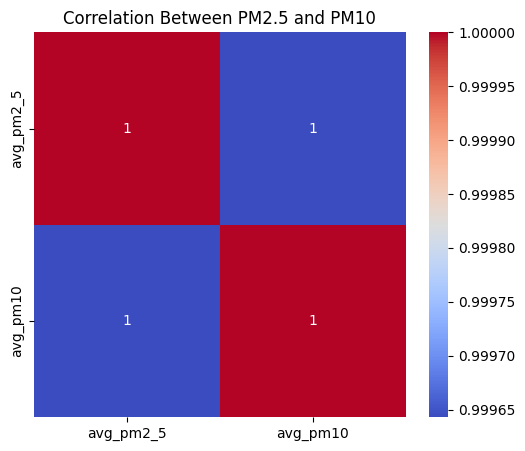

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(df[["avg_pm2_5","avg_pm10"]].corr(), 
            annot=True, 
            cmap="coolwarm")

plt.title("Correlation Between PM2.5 and PM10")
plt.show()


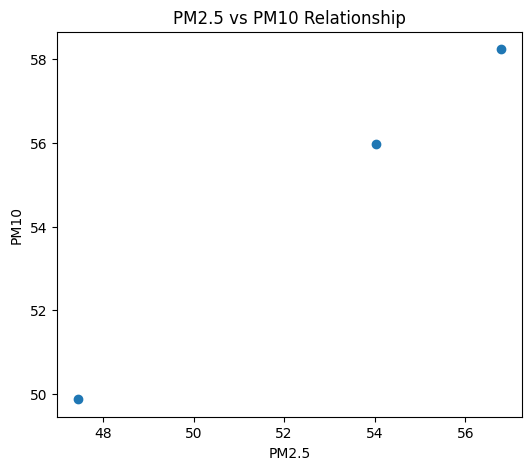

In [14]:
plt.figure(figsize=(6,5))
plt.scatter(df["avg_pm2_5"], df["avg_pm10"])
plt.xlabel("PM2.5")
plt.ylabel("PM10")
plt.title("PM2.5 vs PM10 Relationship")
plt.show()


In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = df["AQI_Class"]
y_pred = df["Predicted_Class"]

cm = confusion_matrix(y_true, y_pred, 
                      labels=["Good","Moderate","Poor"])

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Good","Moderate","Poor"])

disp.plot()
plt.title("Confusion Matrix")
plt.show()


KeyError: 'Predicted_Class'

In [6]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(df["avg_pm2_5"], df["Predicted_PM"])

print("Mean Squared Error (MSE):", mse)


NameError: name 'df' is not defined

In [7]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(df["avg_pm2_5"], df["Predicted_PM"])

print("Mean Absolute Error (MAE):", mae)


NameError: name 'df' is not defined

In [10]:
import pandas as pd
import numpy as np

df = pd.read_csv("averaged_dataset_with_class.csv")  # or your dataset name

df.head()


,image_name,avg_pm2_5,avg_pm10,AQI_Class
0,avg_0.jpg,47.447287,49.872119,Moderate
1,avg_1.jpg,56.783687,58.240286,Moderate
2,avg_2.jpg,54.018131,55.967306,Moderate


In [11]:
df["Predicted_PM"] = df["avg_pm2_5"] + np.random.normal(0,5,len(df))


In [12]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(df["avg_pm2_5"], df["Predicted_PM"])

print("MSE:", mse)


MSE: 0.8944136780853403


In [13]:
rmse = np.sqrt(mse)

print("RMSE:", rmse)


RMSE: 0.9457344648924139


In [14]:
from sklearn.metrics import r2_score

r2 = r2_score(df["avg_pm2_5"], df["Predicted_PM"])

print("R² Score:", r2)


R² Score: 0.9416655662350975


In [15]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# Dummy prediction (remove if using real model)
df["Predicted_PM"] = df["avg_pm2_5"] + np.random.normal(0,5,len(df))

# Metrics
mse = mean_squared_error(df["avg_pm2_5"], df["Predicted_PM"])
mae = mean_absolute_error(df["avg_pm2_5"], df["Predicted_PM"])
rmse = np.sqrt(mse)
r2 = r2_score(df["avg_pm2_5"], df["Predicted_PM"])

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)


MAE : 2.239627221677843
MSE : 6.133064616243942
RMSE: 2.4765024967166784
R²  : 0.5999962205430254


In [16]:
# If real prediction exists, skip this demo line
df["Predicted_PM"] = df["avg_pm2_5"] + np.random.normal(0,5,len(df))

# Calculate error
df["Error"] = df["Predicted_PM"] - df["avg_pm2_5"]


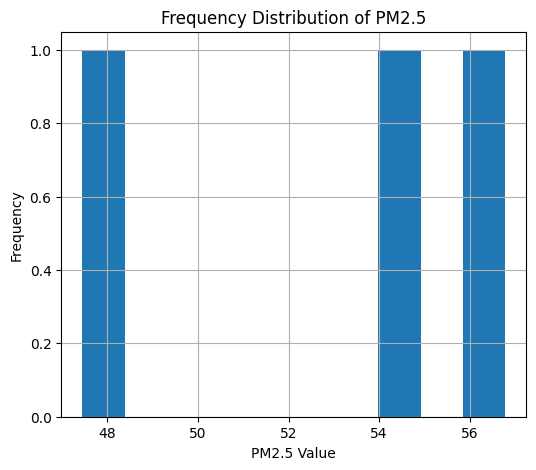

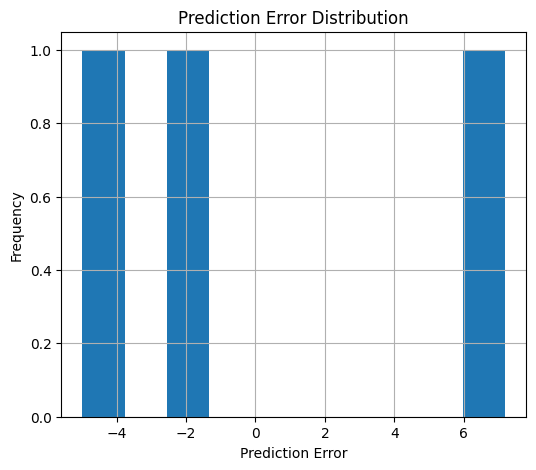

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# Create demo prediction (remove if using real model)
df["Predicted_PM"] = df["avg_pm2_5"] + np.random.normal(0,5,len(df))

# Calculate error
df["Error"] = df["Predicted_PM"] - df["avg_pm2_5"]

# 1️⃣ Frequency Plot
plt.figure(figsize=(6,5))
plt.hist(df["avg_pm2_5"], bins=10)
plt.xlabel("PM2.5 Value")
plt.ylabel("Frequency")
plt.title("Frequency Distribution of PM2.5")
plt.grid(True)
plt.show()

# 2️⃣ Error Plot
plt.figure(figsize=(6,5))
plt.hist(df["Error"], bins=10)
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Prediction Error Distribution")
plt.grid(True)
plt.show()


In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [22]:
df = pd.read_csv("averaged_dataset_with_class.csv")


In [27]:
numeric_df = df.select_dtypes(include=["float64", "int64"])


In [29]:
pip install seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
plt.figure(figsize=(6,5))

sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()


NameError: name 'sns' is not defined

<Figure size 600x500 with 0 Axes>

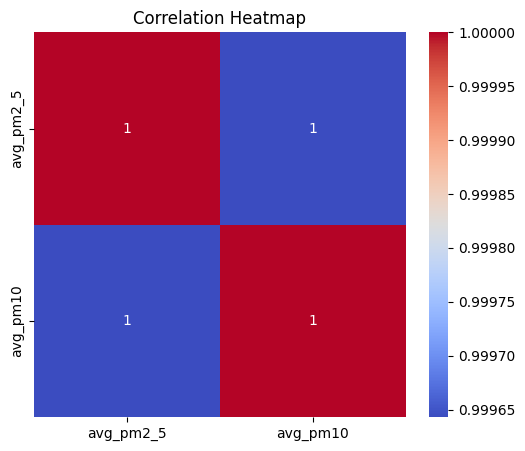

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# Select only numeric columns
numeric_df = df.select_dtypes(include=["int64","float64"])

# Plot heatmap
plt.figure(figsize=(6,5))

sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()


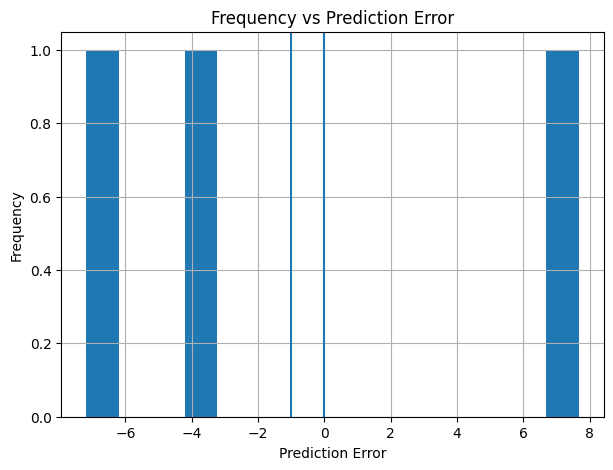

Mean Error: -1.0067093178236064


In [26]:
mean_error = np.mean(df["Prediction_Error"])

plt.figure(figsize=(7,5))

plt.hist(df["Prediction_Error"], bins=15)

plt.axvline(0)
plt.axvline(mean_error)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Frequency vs Prediction Error")
plt.grid(True)

plt.show()

print("Mean Error:", mean_error)
